# STL SAT vs SPOT for Equivalence Checking 

## Pipeline overview
```
manual_review_mapping.csv
         │
         ▼
scale_bound_norm.py      →  data/layer1.csv   (normalised, suitability label)
         │
         ├──  STL_LTL_translation.py  →  data/layer2.csv   (+ ltl_gold, ltl_pred)
         │         │
         │         └──  spot_checker.py   →  data/spot_results.csv
         │
         └──  stlsat_checker.py   →  data/stlsat_results.csv
```

## Key design decisions
- **Horizon**: unbounded G/F bounded with `[0, 100000]` — large enough to be semantically close, allows STLSat to attempt
- **Both tools attempt all 151 pairs** — STLSat on normalised STL, SPOT on LTL abstraction
- **rise/fall**: rewritten to `φ & !Yφ` / `!φ & Yφ` using SPOT's Y (Yesterday) operator
- **abs(expr)**: abstracted to proposition for SPOT, converted to `|expr|` for STLSat
- **H[a,b], O[a,b]**: bounds stripped → `H φ`, `O φ` for SPOT
- **Skipped**: parametric operators (OR_i, distance()), symbolic bounds (G[0,H]), S operator

In [2]:
import os, subprocess, time
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from pathlib import Path

os.chdir('/Users/catharinahente/Downloads/ETH/GitHub/ATIC_NL_STL/ATIC_Equivalence')
Path('data').mkdir(exist_ok=True)
print('Working dir:', os.getcwd())

Working dir: /Users/catharinahente/Downloads/ETH/GitHub/ATIC_NL_STL/ATIC_Equivalence


In [3]:
# run STL Sat directly, no subprocess
from importlib import reload
import stlsat_checker
reload(stlsat_checker)
from stlsat_checker import run_dataset

run_dataset(
    input_path='data/layer1.csv',
    output_path='data/stlsat_results.csv',
    gold_col='gold_normalised',
    pred_col='pred_normalised',
    timeout=50
)

Checking all 151 pairs from layer1.csv ...

  [T] MR-001      TIMEOUT          0.0ms
  [v] MR-002      EQUIVALENT       27.9ms
  [!] MR-003      ERROR            0.0ms
  [!] MR-003      ERROR            0.0ms
  [!] MR-003      ERROR            0.0ms
  [v] MR-004      EQUIVALENT       13.7ms
  [v] MR-004      EQUIVALENT       13.3ms
  [v] MR-004      EQUIVALENT       13.8ms
  [x] MR-005      NON_EQUIVALENT   7.3ms
  [!] MR-006      ERROR            0.0ms
  [!] MR-007      ERROR            8.1ms
  [!] MR-008      ERROR            0.0ms
  [!] MR-009      ERROR            0.0ms
  [!] MR-009      ERROR            0.0ms
  [!] MR-010      ERROR            0.0ms
  [!] MR-010      ERROR            0.0ms
  [!] MR-010      ERROR            0.0ms
  [!] MR-011      ERROR            0.0ms
  [!] MR-012      ERROR            0.0ms
  [!] MR-013      ERROR            0.0ms
  [!] MR-013      ERROR            0.0ms
  [T] MR-014      TIMEOUT          0.0ms
  [T] MR-015      TIMEOUT          0.0ms
  [T] MR-

## Step 1 — Run the full pipeline

In [4]:
from importlib import reload
import spot_checker
reload(spot_checker)
from spot_checker import run

run(
    input_path='data/layer2.csv',
    output_path='data/spot_results.csv'
)

Checking all 151 pairs from layer2.csv ...

  [v] MR-001      EQUIVALENT       4.09ms
  [v] MR-002      EQUIVALENT       0.03ms
  [x] MR-003      NON_EQUIVALENT   6.05ms
  [x] MR-003      NON_EQUIVALENT   0.05ms
  [x] MR-003      NON_EQUIVALENT   0.02ms
  [v] MR-004      EQUIVALENT       0.02ms
  [v] MR-004      EQUIVALENT       0.01ms
  [v] MR-004      EQUIVALENT       0.01ms
  [v] MR-005      EQUIVALENT       0.01ms
  [!] MR-006      ERROR            0.00ms
  [!] MR-007      ERROR            0.00ms
  [x] MR-008      NON_EQUIVALENT   0.33ms
  [v] MR-009      EQUIVALENT       0.02ms
  [v] MR-009      EQUIVALENT       0.02ms
  [v] MR-010      EQUIVALENT       0.02ms
  [v] MR-010      EQUIVALENT       0.01ms
  [v] MR-010      EQUIVALENT       0.01ms
  [v] MR-011      EQUIVALENT       0.02ms
  [v] MR-012      EQUIVALENT       0.01ms
  [x] MR-013      NON_EQUIVALENT   0.56ms
  [x] MR-013      NON_EQUIVALENT   0.02ms
  [v] MR-014      EQUIVALENT       0.01ms
  [x] MR-015      NON_EQUIVALENT

## Step 2 — Load results

In [5]:
layer1  = pd.read_csv('data/layer1.csv')
layer2  = pd.read_csv('data/layer2.csv')
stlsat  = pd.read_csv('data/stlsat_results.csv')
spot    = pd.read_csv('data/spot_results.csv')

print(f'layer1 : {len(layer1)} rows')
print(f'layer2 : {len(layer2)} rows')
print(f'stlsat : {len(stlsat)} rows')
print(f'spot   : {len(spot)} rows')

# parse runtimes
stlsat['ms'] = pd.to_numeric(stlsat.get('duration_ms', pd.Series(dtype=float)), errors='coerce')
spot['ms']   = pd.to_numeric(spot.get('duration_ms', pd.Series(dtype=float)), errors='coerce')

layer1 : 151 rows
layer2 : 151 rows
stlsat : 151 rows
spot   : 151 rows


## Step 3 — Routing summary (layer 1)

In [6]:
routing = layer1['suitability'].value_counts()
print('Layer 1 routing:')
for k, v in routing.items():
    print(f'  {k:10s}: {v:4d}  ({100*v/len(layer1):.1f}%)')

print('\nChanges applied:')
changed_gold = layer1[layer1['gold_changes'].str.len() > 0]['gold_changes'].value_counts()
changed_pred = layer1[layer1['pred_changes'].str.len() > 0]['pred_changes'].value_counts()
print('  Gold:', changed_gold.to_dict())
print('  Pred:', changed_pred.to_dict())

Layer 1 routing:
  spot      :  109  (72.2%)
  stlsat    :   32  (21.2%)
  skip      :   10  (6.6%)

Changes applied:
  Gold: {'Added [0,100000] to unbounded G/F operator(s) (semantic change: G/F[0,100000] is strictly stronger than G/F unbounded — valid for SPOT structural comparison only, not for STLSat exact check)': 74, 'Contains rise()/fall() — will be rewritten to Y operator for SPOT.': 34}
  Pred: {'Added [0,100000] to unbounded G/F operator(s) (semantic change: G/F[0,100000] is strictly stronger than G/F unbounded — valid for SPOT structural comparison only, not for STLSat exact check)': 71, 'Contains rise()/fall() — will be rewritten to Y operator for SPOT.': 37}


In [7]:
skip = layer1[layer1['suitability'] == 'skip']
print(f'Total skipped: {len(skip)}')
print()
print(skip['warnings'].value_counts().to_string())

Total skipped: 10

warnings
Contains parametric/indexed operator (OR_i, AND_{i<j}, distance()) — not supported by STLSat or SPOT.; Contains parametric/indexed operator (OR_i, AND_{i<j}, distance()) — not supported by STLSat or SPOT.              6
Contains symbolic interval bound (e.g. G[0,H]) — STLSat requires integer bounds. Cannot safely substitute.; Contains symbolic interval bound (e.g. G[0,H]) — STLSat requires integer bounds. Cannot safely substitute.    4


## Step 4 — Verdict comparison

In [8]:
def verdict_counts(df, label):
    vc = df['equiv_verdict'].value_counts()
    total = len(df)
    print(f'{label} ({total} pairs):')
    for v in ['EQUIVALENT', 'NON_EQUIVALENT', 'ERROR']:
        n = vc.get(v, 0)
        print(f'  {v:15s}: {n:4d}  ({100*n/total:.1f}%)')
    return vc

sc = verdict_counts(stlsat, 'STLSat')
print()
sp = verdict_counts(spot,   'SPOT')

STLSat (151 pairs):
  EQUIVALENT     :   22  (14.6%)
  NON_EQUIVALENT :   22  (14.6%)
  ERROR          :   58  (38.4%)

SPOT (151 pairs):
  EQUIVALENT     :   88  (58.3%)
  NON_EQUIVALENT :   44  (29.1%)
  ERROR          :   19  (12.6%)


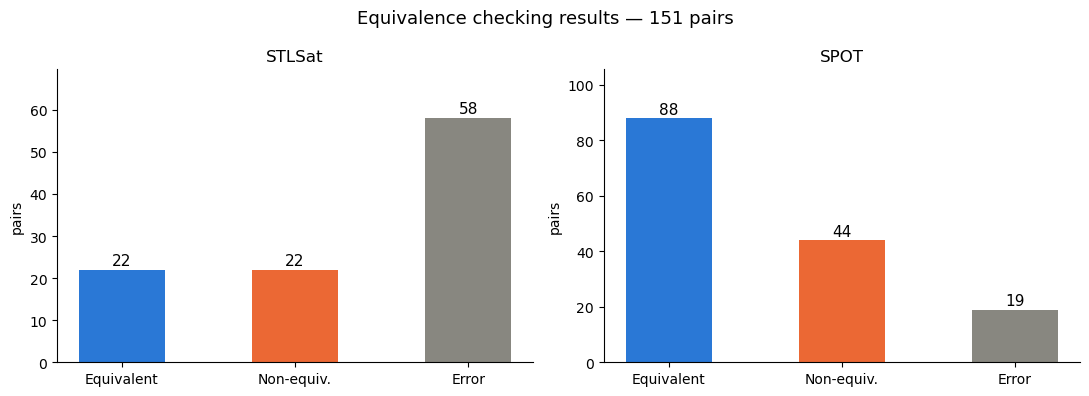

In [9]:
# --- Figure 1: verdict comparison bar chart ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
fig.suptitle('Equivalence checking results — 151 pairs', fontsize=13, fontweight='500')

colors = {'EQUIVALENT': '#2a78d6', 'NON_EQUIVALENT': '#eb6834', 'ERROR': '#888780'}
verdicts = ['EQUIVALENT', 'NON_EQUIVALENT', 'ERROR']
labels   = ['Equivalent', 'Non-equiv.', 'Error']

for ax, df, title in [(axes[0], stlsat, 'STLSat'), (axes[1], spot, 'SPOT')]:
    vc = df['equiv_verdict'].value_counts()
    vals = [vc.get(v, 0) for v in verdicts]
    bars = ax.bar(labels, vals,
                  color=[colors[v] for v in verdicts],
                  width=0.5, edgecolor='none')
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                str(val), ha='center', va='bottom', fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.set_ylim(0, max(vals) * 1.2)
    ax.spines[['top','right']].set_visible(False)
    ax.set_ylabel('pairs')

plt.tight_layout()
plt.show()

## Step 5 — Error breakdown

In [10]:
print('=== STLSat error reasons ===')
stlsat_err = stlsat[stlsat['equiv_verdict'] == 'ERROR']
print(stlsat_err['equiv_detail'].str[:80].value_counts().to_string())

print('\n=== SPOT error reasons ===')
spot_err = spot[spot['equiv_verdict'] == 'ERROR']
print(spot_err['equiv_detail'].str[:80].value_counts().to_string())

=== STLSat error reasons ===
equiv_detail
phi1: rise()/fall() — not supported by STLSat.                                       33
phi1: Past operator H[]/O[] — not supported by STLSat.                                6
phi1: Parametric/indexed operator (OR_i, distance()) — not supported by STLSat.       6
phi1: Symbolic interval bound (e.g. G[0,H]) — STLSat requires integer bounds.         4
phi2: rise()/fall() — not supported by STLSat.                                        3
Unexpected output: \nthread 'main' (6640184) panicked at src/sat/tableau/mod.rs:1     1
Unexpected output: \nthread 'main' (6649359) panicked at src/sat/tableau/mod.rs:1     1
Unexpected output: \nthread 'main' (6665216) panicked at src/sat/tableau/mod.rs:1     1
Unexpected output: \nthread 'main' (6665219) panicked at src/sat/tableau/mod.rs:1     1
Unexpected output: \nthread 'main' (6665221) panicked at src/sat/tableau/mod.rs:1     1
Unexpected output: \nthread 'main' (6668475) panicked at src/sat/tableau/mod.r

In [25]:
spot = pd.read_csv('data/spot_results.csv')
layer2 = pd.read_csv('data/layer2.csv')

spot_err_idx = spot[spot['equiv_verdict'] == 'ERROR'].index
err_rows = layer2.iloc[spot_err_idx]
for _, r in err_rows.drop_duplicates('review_id').head(5).iterrows():
    print(f"{r['review_id']}")
    print(f"  ltl_gold: {r['ltl_gold'][:100]}")
    print(f"  ltl_pred: {r['ltl_pred'][:100]}")
    print()

MR-006
  ltl_gold: G((reset) -> H(!fault))
  ltl_pred: G(reset -> H(!fault))

MR-007
  ltl_gold: (warning) S (loss_of_signal)
  ltl_pred: (warning) S (loss_of_signal)

MR-019
  ltl_gold: G(((x1 + x2) <= 1.5) U(x3_gt_2))
  ltl_pred: G((x1 + x2_le_1p5) U (x3_gt_2))

MR-022
  ltl_gold: G(((x1 + x2) <= 1.5) U(x3_gt_2))
  ltl_pred: G((x1 + x2_le_1p5) | F(x3_gt_2))

MR-027
  ltl_gold: G((grant) -> O(request))
  ltl_pred: G(grant -> O(request))



In [28]:
import importlib
import spot as spot_lib

for formula in [
    'G(H(p))',           # H — Historically
    'p S q',             # S — Since  
    'G(O(p))',           # O — Once
]:
    try:
        result = spot_lib.are_equivalent(formula, formula)
        print(f"OK  : {formula}")
    except Exception as e:
        print(f"FAIL: {formula}  →  {str(e)[:60]}")

FAIL: G(H(p))  →  in method 'are_equivalent', argument 1 of type 'spot::formul
FAIL: p S q  →  in method 'are_equivalent', argument 1 of type 'spot::formul
FAIL: G(O(p))  →  in method 'are_equivalent', argument 1 of type 'spot::formul


## Step 6 — Runtime comparison

In [11]:
stlsat_ms = stlsat['ms'].dropna()
spot_ms   = spot['ms'].dropna()

print('Runtime per pair (ms):')
print(f'  STLSat — mean: {stlsat_ms.mean():.1f}  median: {stlsat_ms.median():.1f}  '
      f'max: {stlsat_ms.max():.1f}  total: {stlsat_ms.sum():.0f}ms')
print(f'  SPOT   — mean: {spot_ms.mean():.1f}  median: {spot_ms.median():.1f}  '
      f'max: {spot_ms.max():.1f}  total: {spot_ms.sum():.0f}ms')

Runtime per pair (ms):
  STLSat — mean: 363.8  median: 0.0  max: 13714.5  total: 54926ms
  SPOT   — mean: 0.1  median: 0.0  max: 6.1  total: 16ms


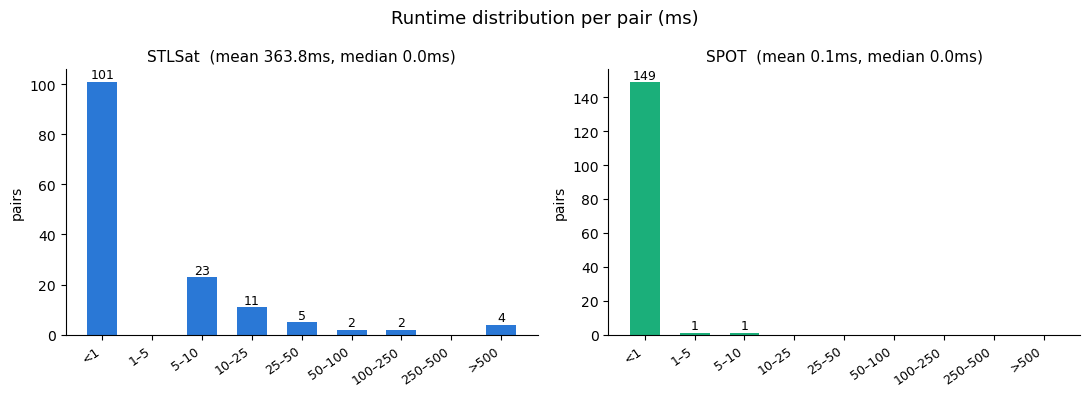

In [12]:
# --- Figure 2: runtime distributions ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
fig.suptitle('Runtime distribution per pair (ms)', fontsize=13, fontweight='500')

bins = [0, 1, 5, 10, 25, 50, 100, 250, 500, 10001]
bin_labels = ['<1','1–5','5–10','10–25','25–50','50–100','100–250','250–500','>500']

for ax, ms, color, title in [
    (axes[0], stlsat_ms, '#2a78d6', 'STLSat'),
    (axes[1], spot_ms,   '#1baf7a', 'SPOT'),
]:
    counts, _ = np.histogram(ms, bins=bins)
    bars = ax.bar(range(len(counts)), counts, color=color,
                  width=0.6, edgecolor='none')
    for bar, val in zip(bars, counts):
        if val > 0:
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
                    str(val), ha='center', va='bottom', fontsize=9)
    ax.set_xticks(range(len(bin_labels)))
    ax.set_xticklabels(bin_labels, rotation=35, ha='right', fontsize=9)
    ax.set_title(f'{title}  (mean {ms.mean():.1f}ms, median {ms.median():.1f}ms)',
                 fontsize=11)
    ax.set_ylabel('pairs')
    ax.spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.show()

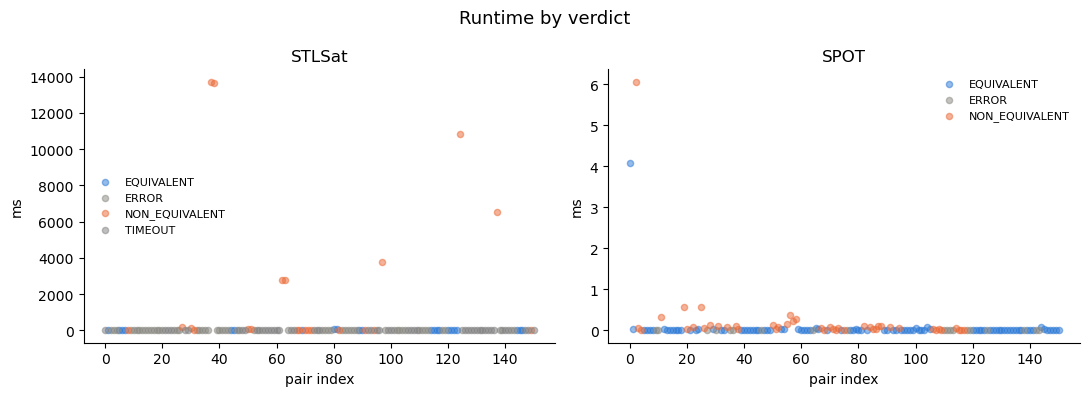

In [13]:
# --- Figure 3: runtime by verdict ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
fig.suptitle('Runtime by verdict', fontsize=13, fontweight='500')

palette = {'EQUIVALENT': '#2a78d6', 'NON_EQUIVALENT': '#eb6834', 'ERROR': '#888780'}

for ax, df, title in [(axes[0], stlsat, 'STLSat'), (axes[1], spot, 'SPOT')]:
    df_t = df.dropna(subset=['ms'])
    for verdict, grp in df_t.groupby('equiv_verdict'):
        ax.scatter(grp.index, grp['ms'],
                   color=palette.get(verdict, 'gray'),
                   alpha=0.5, s=20, label=verdict)
    ax.set_title(title, fontsize=12)
    ax.set_ylabel('ms')
    ax.set_xlabel('pair index')
    ax.spines[['top','right']].set_visible(False)
    ax.legend(fontsize=8, frameon=False)

plt.tight_layout()
plt.show()

In [23]:
stlsat = pd.read_csv('data/stlsat_results.csv')
stlsat['ms'] = pd.to_numeric(stlsat['duration_ms'], errors='coerce')

# sort by runtime descending
slow = stlsat[stlsat['ms'] > 1000].sort_values('ms', ascending=False)
print(f"Pairs taking >1s: {len(slow)}")
print()
for _, r in slow.iterrows():
    print(f"  {r['review_id']:10s}  {r['ms']:.0f}ms  {r['equiv_verdict']:15s}  {str(r['equiv_detail'])[:60]}")

Pairs taking >1s: 7

  MR-028      13714ms  NON_EQUIVALENT   NOT equivalent (XOR is SAT).
  MR-028      13673ms  NON_EQUIVALENT   NOT equivalent (XOR is SAT).
  MR-089      10847ms  NON_EQUIVALENT   NOT equivalent (XOR is SAT).
  MR-100      6542ms  NON_EQUIVALENT   NOT equivalent (XOR is SAT).
  MR-074      3759ms  NON_EQUIVALENT   NOT equivalent (XOR is SAT).
  MR-047      2761ms  NON_EQUIVALENT   NOT equivalent (XOR is SAT).
  MR-047      2748ms  NON_EQUIVALENT   NOT equivalent (XOR is SAT).


In [24]:
layer1 = pd.read_csv('data/layer1.csv')
slow_ids = ['MR-028', 'MR-089', 'MR-100', 'MR-074', 'MR-047']
for rid in slow_ids:
    row = layer1[layer1['review_id'] == rid].iloc[0]
    print(f"{rid}")
    print(f"  gold: {row['gold_normalised']}")
    print(f"  pred: {row['pred_normalised']}")
    print()

MR-028
  gold: G[0,100000](((A = 1) | ((B = 1) & (C = 0))) -> F[0,2](D = 1))
  pred: G[0,100000](((A | B) & !C) -> F[0,2](D))

MR-089
  gold: F[0,120](sample_region & F[0,120](communication_region))
  pred: F[0,120](sample_region & F[0,100000](communication_region))

MR-100
  gold: G[0,100000]((door_close_event & in_doorway) -> F[0,2](!(in_doorway)))
  pred: G[0,100000](((door_close_event = 1) & (in_doorway = 1)) -> F[0,2](in_doorway = 0))

MR-074
  gold: G[0,100000]((soc < 15) -> F[0,1](load_connected = 0))
  pred: G[0,100000]((soc < 15) -> F[0,1](!load_connected))

MR-047
  gold: G[0,100000](proceed -> ((light_green = 1) & (pedestrian_in_crosswalk = 0)))
  pred: G[0,100000](proceed -> (light_green & !pedestrian_in_crosswalk))



## Step 7 — Agreement between tools

In [14]:
# merge on review_id to compare verdicts
merged = stlsat[['review_id','equiv_verdict','ms']].copy()
merged.columns = ['review_id','stlsat_verdict','stlsat_ms']
merged = merged.merge(
    spot[['review_id','equiv_verdict','ms']].rename(
        columns={'equiv_verdict':'spot_verdict','ms':'spot_ms'}),
    on='review_id', how='inner'
)

# both resolved (not ERROR)
both_resolved = merged[
    (merged['stlsat_verdict'] != 'ERROR') &
    (merged['spot_verdict']   != 'ERROR')
]
agree    = both_resolved[both_resolved['stlsat_verdict'] == both_resolved['spot_verdict']]
disagree = both_resolved[both_resolved['stlsat_verdict'] != both_resolved['spot_verdict']]

print(f'Both tools resolved : {len(both_resolved)} pairs')
print(f'  Agree    : {len(agree)} ({100*len(agree)/max(len(both_resolved),1):.1f}%)')
print(f'  Disagree : {len(disagree)} ({100*len(disagree)/max(len(both_resolved),1):.1f}%)')

if len(disagree) > 0:
    print('\nDisagreeing pairs:')
    for _, r in disagree.iterrows():
        print(f'  {r["review_id"]:10s}  STLSat={r["stlsat_verdict"]}  SPOT={r["spot_verdict"]}')

Both tools resolved : 163 pairs
  Agree    : 63 (38.7%)
  Disagree : 100 (61.3%)

Disagreeing pairs:
  MR-001      STLSat=TIMEOUT  SPOT=EQUIVALENT
  MR-005      STLSat=NON_EQUIVALENT  SPOT=EQUIVALENT
  MR-014      STLSat=TIMEOUT  SPOT=EQUIVALENT
  MR-015      STLSat=TIMEOUT  SPOT=NON_EQUIVALENT
  MR-016      STLSat=TIMEOUT  SPOT=EQUIVALENT
  MR-020      STLSat=TIMEOUT  SPOT=NON_EQUIVALENT
  MR-021      STLSat=TIMEOUT  SPOT=EQUIVALENT
  MR-034      STLSat=TIMEOUT  SPOT=EQUIVALENT
  MR-035      STLSat=TIMEOUT  SPOT=EQUIVALENT
  MR-036      STLSat=TIMEOUT  SPOT=EQUIVALENT
  MR-040      STLSat=TIMEOUT  SPOT=EQUIVALENT
  MR-040      STLSat=TIMEOUT  SPOT=EQUIVALENT
  MR-040      STLSat=TIMEOUT  SPOT=EQUIVALENT
  MR-040      STLSat=TIMEOUT  SPOT=EQUIVALENT
  MR-042      STLSat=TIMEOUT  SPOT=NON_EQUIVALENT
  MR-043      STLSat=TIMEOUT  SPOT=NON_EQUIVALENT
  MR-044      STLSat=TIMEOUT  SPOT=NON_EQUIVALENT
  MR-045      STLSat=TIMEOUT  SPOT=EQUIVALENT
  MR-045      STLSat=TIMEOUT  SPOT=EQUIVALEN

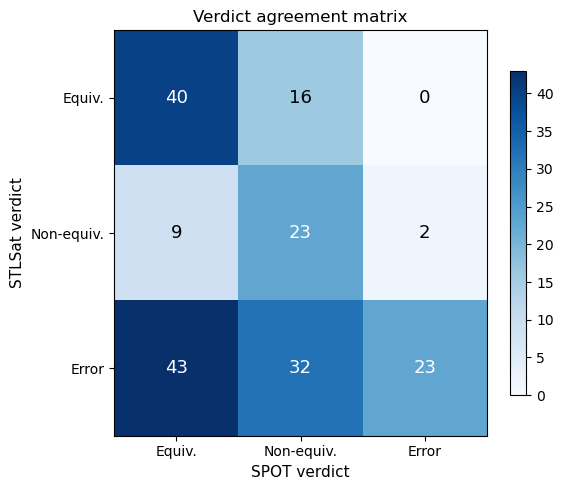

In [15]:
# --- Figure 4: agreement heatmap ---
verdicts = ['EQUIVALENT', 'NON_EQUIVALENT', 'ERROR']
matrix = pd.crosstab(merged['stlsat_verdict'], merged['spot_verdict'])
matrix = matrix.reindex(index=verdicts, columns=verdicts, fill_value=0)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(matrix.values, cmap='Blues', aspect='auto')

ax.set_xticks(range(len(verdicts)))
ax.set_yticks(range(len(verdicts)))
ax.set_xticklabels(['Equiv.','Non-equiv.','Error'], fontsize=10)
ax.set_yticklabels(['Equiv.','Non-equiv.','Error'], fontsize=10)
ax.set_xlabel('SPOT verdict', fontsize=11)
ax.set_ylabel('STLSat verdict', fontsize=11)
ax.set_title('Verdict agreement matrix', fontsize=12)

for i in range(len(verdicts)):
    for j in range(len(verdicts)):
        val = matrix.values[i, j]
        ax.text(j, i, str(val), ha='center', va='center',
                fontsize=13, fontweight='500',
                color='white' if val > matrix.values.max()*0.5 else 'black')

plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

## Step 8 — Equivalent pairs found

In [16]:
# pairs where at least one tool says EQUIVALENT
stlsat_eq = set(stlsat[stlsat['equiv_verdict']=='EQUIVALENT']['review_id'])
spot_eq   = set(spot[spot['equiv_verdict']=='EQUIVALENT']['review_id'])
both_eq   = stlsat_eq & spot_eq
only_stlsat = stlsat_eq - spot_eq
only_spot   = spot_eq - stlsat_eq
either_eq   = stlsat_eq | spot_eq

print(f'EQUIVALENT by STLSat only : {len(only_stlsat)}')
print(f'EQUIVALENT by SPOT only   : {len(only_spot)}')
print(f'EQUIVALENT by both        : {len(both_eq)}')
print(f'EQUIVALENT by either      : {len(either_eq)}')

print('\nPairs confirmed equivalent by BOTH tools:')
for rid in sorted(both_eq):
    row = layer1[layer1['review_id']==rid].iloc[0]
    print(f'  {rid}')
    print(f'    gold : {row["gold_formula"]}')
    print(f'    pred : {row["predicted_formula"]}')

EQUIVALENT by STLSat only : 1
EQUIVALENT by SPOT only   : 55
EQUIVALENT by both        : 11
EQUIVALENT by either      : 67

Pairs confirmed equivalent by BOTH tools:
  MR-002
    gold : (door_closed = 1) & F[0,2](lock_confirmed = 1)
    pred : door_closed & F[0,2](lock_confirmed)
  MR-004
    gold : (!(hazard_zone = 1)) U[0,60] (charging_station = 1)
    pred : (!hazard_zone) U[0,60] (charging_station)
  MR-032
    gold : G(((A = 1) & !(A = 1)) -> F[0,2](B = 1))
    pred : G((A & !A) -> F[0,2](B))
  MR-052
    gold : F[0,60](package_at_station_B = 1)
    pred : F[0,60](package_at_station_B)
  MR-061
    gold : G[10,150]((x1 > 0.2) -> F[0,30](x2 < 0.5))
    pred : G[10,150]((x1 > 0.2) -> F[0,30](x2 < 0.5))
  MR-062
    gold : G[10,150]((x1 > 0.2) -> F[0,30](x2 < 0.5))
    pred : G[10,150]((x1 > 0.2) -> F[0,30](x2 < 0.5))
  MR-068
    gold : F[0,60](station_any_r1) & F[0,60](station_any_r2) & F[0,60](station_any_r3)
    pred : F[0,60](station_any_r1 = 1) & F[0,60](station_any_r2 = 1) & F

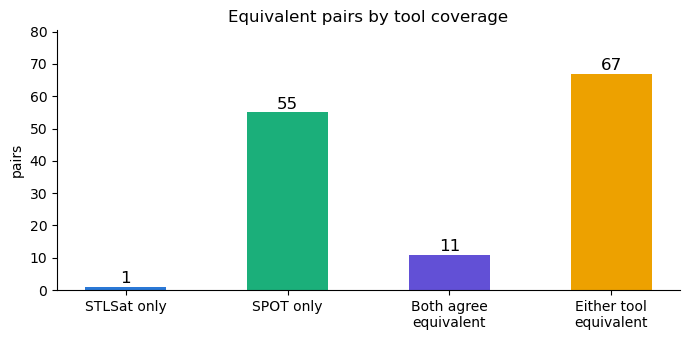

In [17]:
# --- Figure 5: Venn-style bar of coverage ---
fig, ax = plt.subplots(figsize=(7, 3.5))

categories = ['STLSat only', 'SPOT only', 'Both agree\nequivalent', 'Either tool\nequivalent']
values     = [len(only_stlsat), len(only_spot), len(both_eq), len(either_eq)]
bar_colors = ['#2a78d6', '#1baf7a', '#6250d6', '#eda100']

bars = ax.bar(categories, values, color=bar_colors, width=0.5, edgecolor='none')
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
            str(val), ha='center', va='bottom', fontsize=12)

ax.set_title('Equivalent pairs by tool coverage', fontsize=12)
ax.set_ylabel('pairs')
ax.set_ylim(0, max(values) * 1.2)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

## Step 9 — Full summary

In [21]:
total = len(layer1)
skip  = (layer1['suitability'] == 'skip').sum()

stlsat_eq_n  = (stlsat['equiv_verdict'] == 'EQUIVALENT').sum()
stlsat_neq_n = (stlsat['equiv_verdict'] == 'NON_EQUIVALENT').sum()
stlsat_err_n = (stlsat['equiv_verdict'] == 'ERROR').sum()

spot_eq_n    = (spot['equiv_verdict'] == 'EQUIVALENT').sum()
spot_neq_n   = (spot['equiv_verdict'] == 'NON_EQUIVALENT').sum()
spot_err_n   = (spot['equiv_verdict'] == 'ERROR').sum()

print('=' * 55)
print(f'FULL PIPELINE SUMMARY  ({total} pairs)')
print('=' * 55)
print(f'  Skipped (parametric/symbolic/S) : {skip}')
print()
print(f'  {'':20s}  STLSat    SPOT')
print(f'  {"EQUIVALENT":20s}  {stlsat_eq_n:6d}    {spot_eq_n:4d}')
print(f'  {"NON_EQUIVALENT":20s}  {stlsat_neq_n:6d}    {spot_neq_n:4d}')
print(f'  {"ERROR":20s}  {stlsat_err_n:6d}    {spot_err_n:4d}')
print()
print(f'  Avg runtime (ms)         {stlsat_ms.mean():7.1f}    {spot_ms.mean():5.1f}')
print(f'  Median runtime (ms)      {stlsat_ms.median():7.1f}    {spot_ms.median():5.1f}')
print(f'  Max runtime (ms)         {stlsat_ms.max():7.1f}    {spot_ms.max():5.1f}')
print()
print(f'  Equivalent by either tool : {len(either_eq)}')
print(f'  Equivalent by both tools  : {len(both_eq)}')
print('=' * 55)

FULL PIPELINE SUMMARY  (151 pairs)
  Skipped (parametric/symbolic/S) : 10

                        STLSat    SPOT
  EQUIVALENT                22      88
  NON_EQUIVALENT            22      44
  ERROR                     58      19

  Avg runtime (ms)           363.8      0.1
  Median runtime (ms)          0.0      0.0
  Max runtime (ms)         13714.5      6.1

  Equivalent by either tool : 67
  Equivalent by both tools  : 11


In [22]:
stlsat = pd.read_csv('data/stlsat_results.csv').reset_index(drop=True)
spot   = pd.read_csv('data/spot_results.csv').reset_index(drop=True)
layer1 = pd.read_csv('data/layer1.csv').reset_index(drop=True)

# all pairs where STLSat gave a real verdict
stlsat_resolved_mask = stlsat['equiv_verdict'].isin(['EQUIVALENT','NON_EQUIVALENT'])

comparison = pd.DataFrame({
    'review_id':      layer1['review_id'],
    'suitability':    layer1['suitability'],
    'stlsat_verdict': stlsat['equiv_verdict'],
    'spot_verdict':   spot['equiv_verdict'],
    'gold':           layer1['gold_formula'],
    'pred':           layer1['predicted_formula'],
})

# pairs STLSat resolved
stlsat_resolved = comparison[stlsat_resolved_mask]
both_resolved   = stlsat_resolved[stlsat_resolved['spot_verdict'].isin(['EQUIVALENT','NON_EQUIVALENT'])]

agree    = both_resolved[both_resolved['stlsat_verdict'] == both_resolved['spot_verdict']]
disagree = both_resolved[both_resolved['stlsat_verdict'] != both_resolved['spot_verdict']]

print(f"Total pairs              : {len(comparison)}")
print(f"STLSat resolved          : {len(stlsat_resolved)}")
print(f"Both tools resolved      : {len(both_resolved)}")
print(f"  Agree    : {len(agree)}  ({100*len(agree)/max(len(both_resolved),1):.1f}%)")
print(f"  Disagree : {len(disagree)}  ({100*len(disagree)/max(len(both_resolved),1):.1f}%)")

if len(disagree) > 0:
    print("\nDisagreeing pairs (potential arithmetic difference):")
    for _, r in disagree.iterrows():
        print(f"  {r['review_id']:10s}  suitability={r['suitability']:8s}  STLSat={r['stlsat_verdict']:15s}  SPOT={r['spot_verdict']}")
        print(f"    gold : {r['gold']}")
        print(f"    pred : {r['pred']}")

Total pairs              : 151
STLSat resolved          : 44
Both tools resolved      : 42
  Agree    : 31  (73.8%)
  Disagree : 11  (26.2%)

Disagreeing pairs (potential arithmetic difference):
  MR-005      suitability=stlsat    STLSat=NON_EQUIVALENT   SPOT=EQUIVALENT
    gold : (!(hazard_zone = 1)) U[0,60] (charging_station = 1)
    pred : (hazard_zone = 0) U[0,60] (charging_station = 1)
  MR-047      suitability=spot      STLSat=NON_EQUIVALENT   SPOT=EQUIVALENT
    gold : G(proceed -> ((light_green = 1) & (pedestrian_in_crosswalk = 0)))
    pred : G(proceed -> (light_green & !pedestrian_in_crosswalk))
  MR-047      suitability=spot      STLSat=NON_EQUIVALENT   SPOT=EQUIVALENT
    gold : G(proceed -> ((light_green = 1) & (pedestrian_in_crosswalk = 0)))
    pred : G(proceed -> (light_green & !pedestrian_in_crosswalk))
  MR-074      suitability=spot      STLSat=NON_EQUIVALENT   SPOT=EQUIVALENT
    gold : G((soc < 15) -> F[0,1](load_connected = 0))
    pred : G((soc < 15) -> F[0,1](!lo